# Part 2: Does the optimiser hold up, and what drives energy stocks?

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
from src.config import (BENCHMARK, COMMODITIES, LOOKBACK_YEARS,
                        REBALANCE_FREQ, TICKERS, TRAIN_END)
from src.data import load_commodities, load_prices
from src import backtest, commodities, metrics, plots

pd.options.display.float_format = "{:.3f}".format

prices = metrics.clean_prices(load_prices())
returns = metrics.daily_returns(prices)
market = returns.pop(BENCHMARK)

## 1. Out-of-sample test

In [2]:
weights, test_returns = backtest.out_of_sample(returns, TRAIN_END)
weights[(weights > 0.005).any(axis=1)]

,Max Sharpe,Max Sharpe (25% cap),Min variance,Equal weight
XOM,0.653,0.250,0.050,0.083
CVX,0.000,0.042,0.054,0.083
SHEL,0.000,0.126,0.004,0.083
BP,0.000,0.000,0.000,0.083
TTE,0.000,0.139,0.124,0.083
NEE,0.000,0.000,0.000,0.083
DUK,0.000,0.000,0.309,0.083
SO,0.106,0.211,0.136,0.083
NGG,0.119,0.100,0.205,0.083
FSLR,0.122,0.131,0.021,0.083


In [3]:
test_market = market.loc[test_returns.index]
pd.concat([metrics.summary_table(test_returns, test_market),
           metrics.summary_table(test_market.to_frame(), test_market)])

,Annual return,Volatility,Sharpe,Max drawdown,Beta
Max Sharpe,0.153,0.169,0.669,-0.186,0.407
Max Sharpe (25% cap),0.136,0.150,0.637,-0.165,0.385
Min variance,0.125,0.135,0.627,-0.128,0.201
Equal weight,0.083,0.158,0.270,-0.193,0.441
SPY,0.213,0.164,1.060,-0.188,1.000


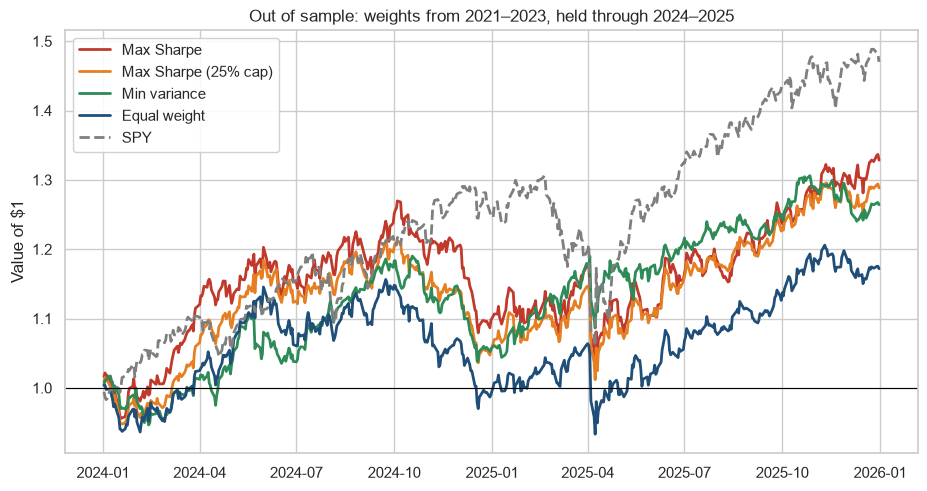

In [4]:
plots.plot_strategy_growth(
    test_returns, market,
    "Out of sample: weights from 2021–2023, held through 2024–2025",
    save_as="oos_growth");

## 2. Rolling quarterly backtest

In [5]:
rolled, history = backtest.rolling_backtest(returns, LOOKBACK_YEARS, REBALANCE_FREQ)
rolled_market = market.loc[rolled.index]
pd.concat([metrics.summary_table(rolled, rolled_market),
           metrics.summary_table(rolled_market.to_frame(), rolled_market)])

,Annual return,Volatility,Sharpe,Max drawdown,Beta
Min variance,0.101,0.138,0.440,-0.138,0.327
Equal weight,0.047,0.170,0.042,-0.201,0.555
Max Sharpe (25% cap),0.002,0.169,-0.224,-0.216,0.407
Max Sharpe,-0.013,0.201,-0.263,-0.254,0.436
SPY,0.230,0.153,1.239,-0.188,1.000


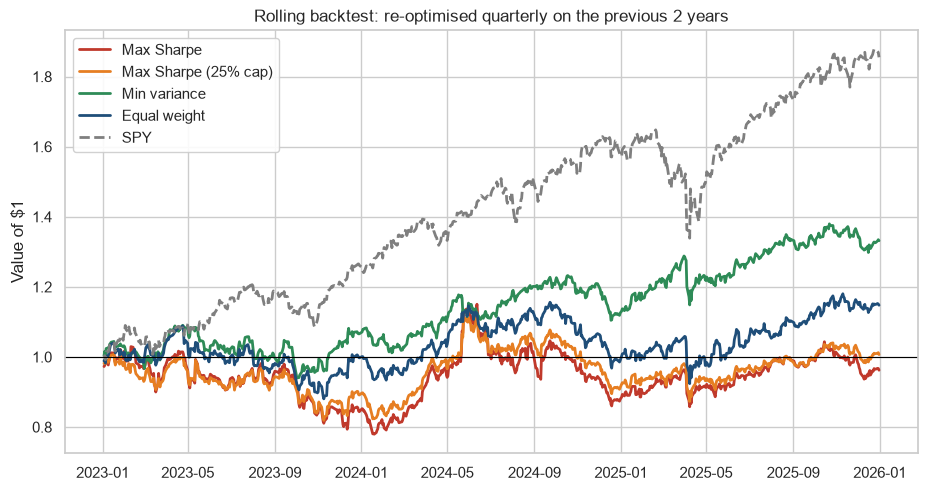

In [6]:
plots.plot_strategy_growth(
    rolled, market,
    "Rolling backtest: re-optimised quarterly on the previous 2 years",
    save_as="rolling_backtest");

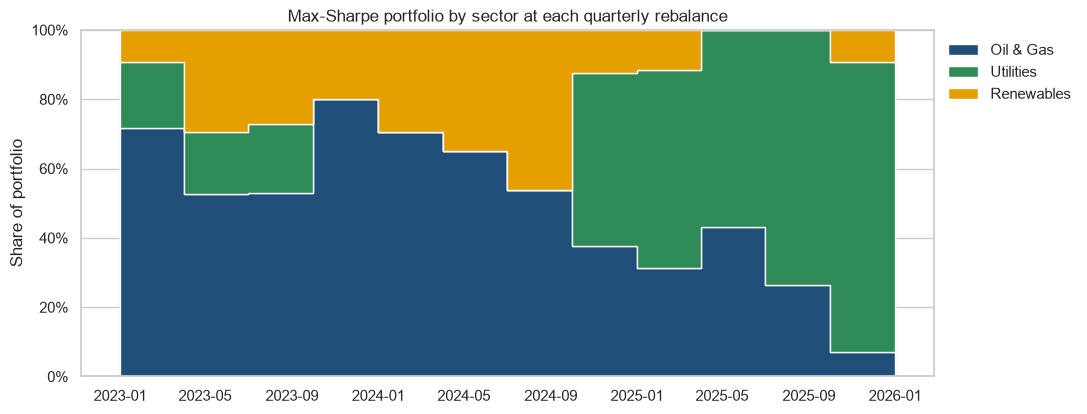

In [7]:
plots.plot_weight_history(history, save_as="weight_history");

## 3. Commodity sensitivity

In [8]:
commodity_prices = load_commodities()
weekly = commodities.combine(prices, commodity_prices)
weekly[list(COMMODITIES)].corr()

,BZ=F,NG=F,TTF=F
BZ=F,1.000,0.116,0.232
NG=F,0.116,1.000,0.118
TTF=F,0.232,0.118,1.000


In [9]:
factors = [BENCHMARK] + list(COMMODITIES)
betas, tstats, r2 = commodities.commodity_betas(weekly, TICKERS, factors)
betas.join(r2)

,SPY,BZ=F,NG=F,TTF=F,R-squared
XOM,0.302,0.547,0.025,0.004,0.486
CVX,0.418,0.463,0.008,0.005,0.448
SHEL,0.333,0.364,0.008,-0.018,0.330
BP,0.312,0.477,0.012,-0.032,0.351
TTE,0.306,0.365,-0.002,-0.033,0.320
NEE,0.696,-0.043,-0.000,0.034,0.169
DUK,0.296,-0.081,0.006,0.025,0.086
SO,0.362,-0.078,0.014,0.021,0.119
NGG,0.490,-0.077,-0.015,0.012,0.151
FSLR,1.032,0.065,0.074,0.016,0.107


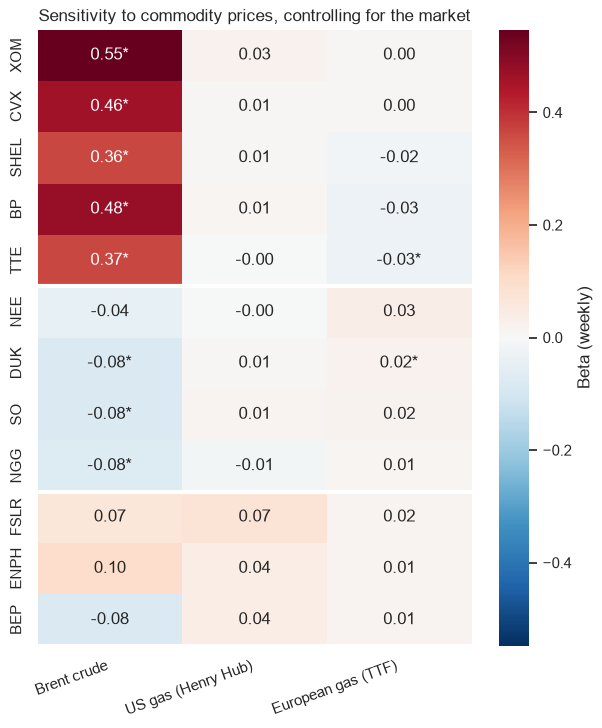

In [10]:
plots.plot_commodity_betas(betas, tstats, COMMODITIES, save_as="commodity_betas");

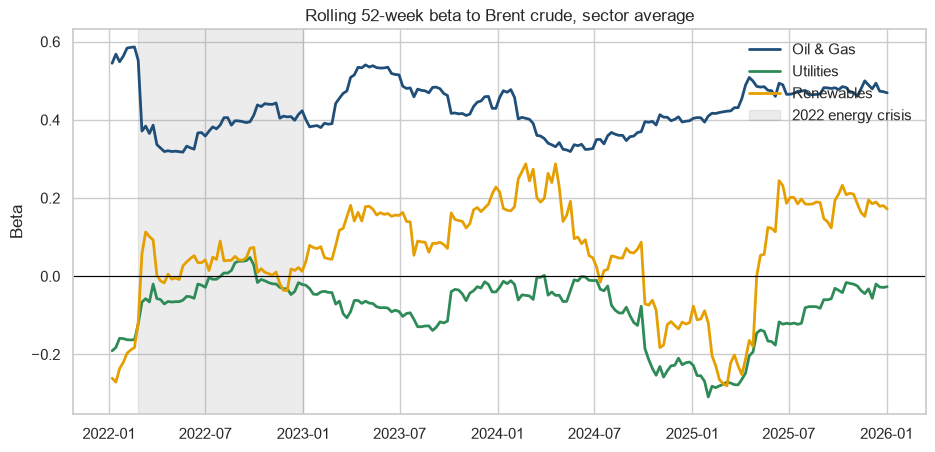

In [11]:
rolling = commodities.rolling_betas(weekly, TICKERS, factors)
plots.plot_rolling_sector_beta(rolling, "BZ=F", COMMODITIES["BZ=F"],
                               save_as="rolling_oil_beta");

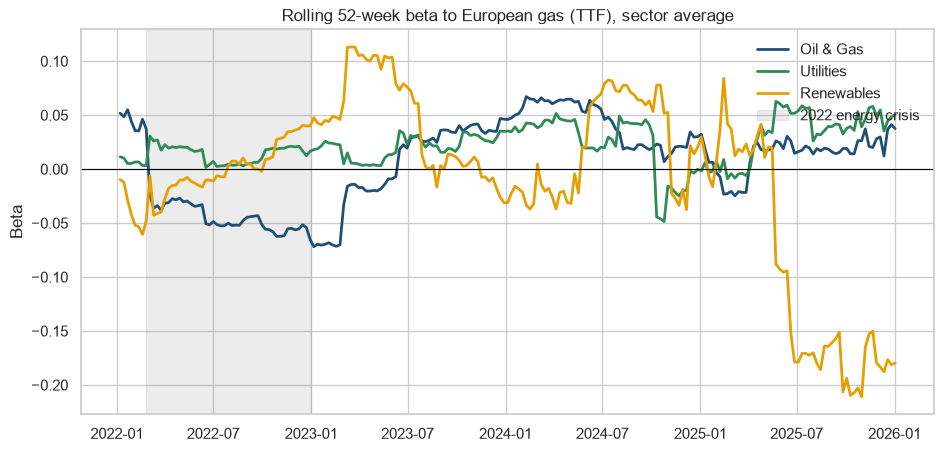

In [12]:
plots.plot_rolling_sector_beta(rolling, "TTF=F", COMMODITIES["TTF=F"],
                               save_as="rolling_gas_beta");